# B — Clustering kejadian & penamaan kelas (Fahmi)

Notebook bagian B, Task 2 Datavidia 11.0.

**Alur:** embedding DINOv2-L (`hafizh/v2`, cabang warna) → PCA → Spectral Clustering per kejadian → gate kualitas →
median indikator fisik per cluster → skor 6 kelas dari `rules.json` (dikunci Fahmi) → nama kejadian → `is_core`.

**Output** (folder versi baru, tidak menimpa): `events.parquet`, `event_names.csv`, `cluster_profile.csv`, `rules.json`, `meta.json`.

Catatan aturan kompetisi: nama kelas ditentukan **hanya oleh aturan kode** di `rules.json`. Tidak ada label manual,
tidak ada penilaian visual gambar, dan aturan tidak diubah setelah melihat skor.

## 0. Library & versi

In [1]:
import json, os, sys, platform
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import SpectralClustering, KMeans
from sklearn.metrics import adjusted_rand_score

# Versi library dicatat untuk meta.json
VERSI_LIB = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pyarrow": pyarrow.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
for k, v in VERSI_LIB.items():
    print(f"{k:13s} {v}")

python        3.12.7
numpy         2.5.5
pandas        3.1.1
pyarrow       26.0.1
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.10.9


## Pengaturan
Semua path dan angka di sini. Path relatif terhadap folder `fahmi/`.

In [2]:
# --- Path input ---
SAMPLE_SUB = "../../sample_submission.csv"     # di luar repo
FITUR_DIR  = "../hafizh/v2"                    # embedding DINOv2-L
PHYS_PATH  = "../hafizh/v3/phys_v4.parquet"    # indikator piksel

# --- Output (jika sudah ada, notebook memakai v2, v3, ... ; tidak menimpa) ---
OUTPUT_DIR = "v1"

# --- Embedding & clustering ---
SEED = 42
PCA_DIM = 64          # dimensi PCA
ROUND = 4             # pembulatan embedding sebelum clustering
K = 20                # jumlah cluster kejadian (spectral)
KNN = 15              # n_neighbors graf spectral
K_KASAR = 8           # KMeans struktur kasar (pengecekan saja)

# --- Penamaan & is_core ---
CORE_FRAC = 0.5       # porsi foto terdekat pusat cluster yang jadi is_core
MIN_WARNA = 15        # minimal foto warna valid per cluster agar median warna dipakai
MARGIN_LEMAH = 0.5    # margin < ini -> cluster lemah

# --- Gate kualitas ---
NOISE_SKALA = 1e-3    # std noise = NOISE_SKALA x std(Z), untuk uji ketahanan
KNN_UJI = 25          # n_neighbors untuk uji ketahanan parameter
GATE_ARI_NOISE = 0.95
GATE_ARI_KNN = 0.80
GATE_BIAS_MAX = 0.15
GATE_MIN_SIZE = 30

# --- Indikator (dari plan.md Tahap 6) ---
IND_STRUKTUR = ["d_dark", "d_entropy",                 # phys_v4
                "delta_edge", "edge_pre",              # artifact_and_phys_v3
                "top10_share", "radial_decay", "com_shift", "frac_chg_p15"]   # patch_change_stats_v3
IND_WARNA    = ["d_exg_v4", "water_rel_pre", "d_water", "d_bright_raw_v4"]  # phys_v4, NaN jika warna tak dipercaya

np.random.seed(SEED)
print("Folder kerja:", os.getcwd())
for p in [SAMPLE_SUB, FITUR_DIR, PHYS_PATH]:
    print(f"{'ada ' if os.path.exists(p) else 'TIDAK ADA'}  {p}")

Folder kerja: d:\Python\Library\Scikit-learn\praktik kaggle\Arkavidia\Task2\Perintis_DATAVIDIA\fahmi
ada   ../../sample_submission.csv
ada   ../hafizh/v2
ada   ../hafizh/v3/phys_v4.parquet


## 1. Muat data & cek input

In [3]:
sub   = pd.read_csv(SAMPLE_SUB)
art   = pd.read_parquet(f"{FITUR_DIR}/artifact_and_phys_v3.parquet")
patch = pd.read_parquet(f"{FITUR_DIR}/patch_change_stats_v3.parquet")
phys  = pd.read_parquet(PHYS_PATH)
emb_pre  = np.load(f"{FITUR_DIR}/dino_color_pre.npy")
emb_post = np.load(f"{FITUR_DIR}/dino_color_post.npy")

ids = sub["Id"].to_numpy()
N = len(ids)

# Cek urutan Id sama persis dengan sample_submission
for nama, df in [("artifact", art), ("patch", patch), ("phys_v4", phys)]:
    assert len(df) == N and (df["Id"].to_numpy() == ids).all(), f"urutan Id {nama} berbeda"
assert sub["Id"].is_unique

# Cek embedding
for nama, e in [("pre", emb_pre), ("post", emb_post)]:
    assert e.shape == (N, 1024), f"bentuk {nama} {e.shape}"
    assert not np.isnan(e).any(), f"NaN di embedding {nama}"

print("N =", N, "| embedding pre/post:", emb_pre.shape, emb_post.shape, emb_pre.dtype)
print("artifact:", art.shape, "| patch:", patch.shape, "| phys_v4:", phys.shape)
print("Semua cek urutan Id, bentuk, dan NaN embedding: LULUS")

N = 3180 | embedding pre/post: (3180, 1024) (3180, 1024) float32
artifact: (3180, 47) | patch: (3180, 28) | phys_v4: (3180, 23)
Semua cek urutan Id, bentuk, dan NaN embedding: LULUS


In [4]:
# Gabung kolom indikator per Id (urutan sudah sama, jadi cukup ambil kolomnya)
sumber = {"d_dark": phys, "d_entropy": phys, "delta_edge": art, "edge_pre": art,
          "top10_share": patch, "radial_decay": patch, "com_shift": patch, "frac_chg_p15": patch,
          "d_exg_v4": phys, "water_rel_pre": phys, "d_water": phys, "d_bright_raw_v4": phys}
ind = pd.DataFrame({"Id": ids})
for c in IND_STRUKTUR + IND_WARNA:
    ind[c] = sumber[c][c].to_numpy()

ringkas = pd.DataFrame({
    "jenis": ["struktur"] * len(IND_STRUKTUR) + ["warna"] * len(IND_WARNA),
    "n_nan": ind[IND_STRUKTUR + IND_WARNA].isna().sum().to_numpy(),
    "min": ind[IND_STRUKTUR + IND_WARNA].min().to_numpy(),
    "median": ind[IND_STRUKTUR + IND_WARNA].median().to_numpy(),
    "max": ind[IND_STRUKTUR + IND_WARNA].max().to_numpy(),
}, index=IND_STRUKTUR + IND_WARNA).round(4)
print("color_unreliable_v4 =", round(phys["color_unreliable_v4"].mean() * 100, 1), "% foto")
ringkas

color_unreliable_v4 = 81.2 % foto


,jenis,n_nan,min,median,max
d_dark,struktur,0,-0.3519,-0.0015,0.4630
d_entropy,struktur,0,-2.0704,-0.0413,1.9442
delta_edge,struktur,0,-0.4163,-0.0165,0.5733
edge_pre,struktur,0,0.0336,0.2470,0.9172
top10_share,struktur,0,0.1608,0.2937,0.4990
radial_decay,struktur,0,-0.3963,0.0528,0.6861
com_shift,struktur,0,0.0018,0.0785,0.5309
frac_chg_p15,struktur,0,0.0640,0.2834,0.7950
d_exg_v4,warna,2583,-0.0824,0.0012,0.0827
water_rel_pre,warna,2583,0.0000,0.0019,0.1976


## 2. Siapkan embedding
L2 per blok → gabung pre+post (2048) → kurangi rata-rata → PCA → bulatkan.

In [5]:
pre  = emb_pre.astype(np.float64)
post = emb_post.astype(np.float64)
pre  = pre  / np.linalg.norm(pre,  axis=1, keepdims=True)    # L2 per blok
post = post / np.linalg.norm(post, axis=1, keepdims=True)

X = np.hstack([pre, post])          # (3180, 2048)
X = X - X.mean(axis=0)              # kurangi rata-rata kolom

pca = PCA(PCA_DIM, random_state=SEED)
Z = np.round(pca.fit_transform(X), ROUND)    # dibulatkan sebelum clustering

evr = pca.explained_variance_ratio_
print("Z:", Z.shape)
print(f"Variansi dijelaskan PCA {PCA_DIM}: {evr.sum():.3f}  (10 komponen pertama: {evr[:10].sum():.3f})")

Z: (3180, 64)
Variansi dijelaskan PCA 64: 0.816  (10 komponen pertama: 0.579)


## 3. Clustering
Utama: Spectral (K kejadian). Struktur kasar: KMeans k = K_KASAR (pengecekan saja).

C:\Users\AcerPredatorHelios16\anaconda3\envs\env_general\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


Ukuran cluster kejadian: {0: 40, 1: 46, 2: 61, 3: 112, 4: 116, 5: 100, 6: 58, 7: 117, 8: 173, 9: 136, 10: 140, 11: 128, 12: 196, 13: 193, 14: 173, 15: 207, 16: 214, 17: 248, 18: 376, 19: 346}
Ukuran struktur kasar  : {0: 480, 1: 554, 2: 529, 3: 225, 4: 476, 5: 179, 6: 326, 7: 411}


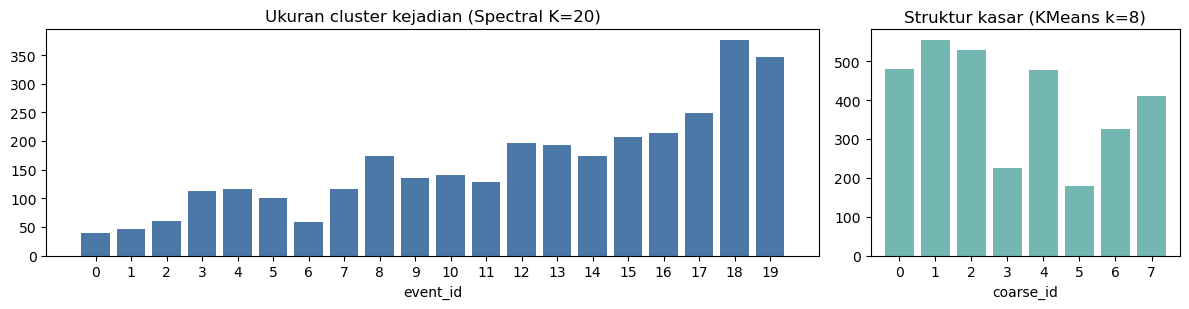

In [6]:
sc = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                        assign_labels="cluster_qr", random_state=SEED)
event_id = sc.fit_predict(Z)

km = KMeans(K_KASAR, n_init=10, random_state=SEED)
coarse_id = km.fit_predict(Z)

ukuran = pd.Series(event_id).value_counts().sort_index()
ukuran_kasar = pd.Series(coarse_id).value_counts().sort_index()
print("Ukuran cluster kejadian:", ukuran.to_dict())
print("Ukuran struktur kasar  :", ukuran_kasar.to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [K, K_KASAR]})
ax[0].bar(ukuran.index, ukuran.values, color="#4C78A8")
ax[0].set_title(f"Ukuran cluster kejadian (Spectral K={K})"); ax[0].set_xlabel("event_id"); ax[0].set_xticks(ukuran.index)
ax[1].bar(ukuran_kasar.index, ukuran_kasar.values, color="#72B7B2")
ax[1].set_title(f"Struktur kasar (KMeans k={K_KASAR})"); ax[1].set_xlabel("coarse_id"); ax[1].set_xticks(ukuran_kasar.index)
plt.tight_layout(); plt.show()

## 4. Gate kualitas
Jika ada cek yang GAGAL, notebook berhenti di sini (ubah K / PCA, jangan lanjut).

η² = Σ n_c (mean_c − mean)² / Σ (x − mean)²  — porsi variasi yang dijelaskan pembagian cluster.

In [7]:
def eta2(label, x):
    # eta kuadrat; baris NaN dilewati
    x = np.asarray(x, dtype=float); ok = ~np.isnan(x)
    lab, x = np.asarray(label)[ok], x[ok]
    m = x.mean(); total = ((x - m) ** 2).sum()
    antar = sum((lab == c).sum() * (x[lab == c].mean() - m) ** 2 for c in np.unique(lab))
    return antar / total if total > 0 else 0.0

# 1) Ketahanan noise: noise normal (std = NOISE_SKALA x std(Z)), seed tetap -> bulatkan -> cluster ulang
rng = np.random.default_rng(SEED)
Z_noise = np.round(Z + rng.normal(0, NOISE_SKALA * Z.std(), Z.shape), ROUND)
lab_noise = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                               assign_labels="cluster_qr", random_state=SEED).fit_predict(Z_noise)
ari_noise = adjusted_rand_score(event_id, lab_noise)

# 2) Ketahanan parameter: n_neighbors = KNN_UJI
lab_knn = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN_UJI,
                             assign_labels="cluster_qr", random_state=SEED).fit_predict(Z)
ari_knn = adjusted_rand_score(event_id, lab_knn)

# 3) Bias artefak
artefak = {
    "is_gray (pre+post)":        art["is_gray_pre"].astype(float) + art["is_gray_post"].astype(float),
    "black_frac (pre+post)":     art["black_frac_pre"] + art["black_frac_post"],
    "scanline_score (pre+post)": art["scanline_score_pre"] + art["scanline_score_post"],
    "color_shift":               phys["color_shift"],
    "|brightness post-pre|":     (art["brightness_post"] - art["brightness_pre"]).abs(),
}
bias = pd.Series({k: eta2(event_id, v) for k, v in artefak.items()}, name="eta2").round(4)
print("η² event_id vs artefak:"); print(bias.to_string(), "\n")

# 4) Ukuran cluster terkecil
min_size = int(ukuran.min())

gate = pd.DataFrame({
    "nilai":  [ari_noise, ari_knn, bias.max(), min_size],
    "target": [f">= {GATE_ARI_NOISE}", f">= {GATE_ARI_KNN}", f"<= {GATE_BIAS_MAX}", f">= {GATE_MIN_SIZE}"],
    "lulus":  [ari_noise >= GATE_ARI_NOISE, ari_knn >= GATE_ARI_KNN,
               bias.max() <= GATE_BIAS_MAX, min_size >= GATE_MIN_SIZE],
}, index=["ARI noise", f"ARI kNN={KNN_UJI}", f"bias maks ({bias.idxmax()})", "ukuran min"])
gate["status"] = np.where(gate["lulus"], "LULUS", "GAGAL")
GATE = {"ari_noise": round(float(ari_noise), 4), "ari_knn25": round(float(ari_knn), 4),
        "bias_max": round(float(bias.max()), 4), "bias_max_kolom": bias.idxmax(), "min_size": min_size,
        "bias_per_artefak": bias.to_dict(), "lulus": bool(gate["lulus"].all())}
display(gate.drop(columns="lulus").round(4))

if not GATE["lulus"]:
    raise RuntimeError("GATE GAGAL -> berhenti. Laporkan ke Fahmi; coba K 15/25 atau PCA 32.")
print("Semua gate LULUS")

η² event_id vs artefak:
is_gray (pre+post)           0.0328
black_frac (pre+post)        0.0245
scanline_score (pre+post)    0.1129
color_shift                  0.0297
|brightness post-pre|        0.0130 



,nilai,target,status
ARI noise,0.9875,>= 0.95,LULUS
ARI kNN=25,0.8603,>= 0.8,LULUS
bias maks (scanline_score (pre+post)),0.1129,<= 0.15,LULUS
ukuran min,40.0000,>= 30,LULUS


Semua gate LULUS


## 5. Indikator & profil cluster
Median setiap indikator per cluster. Indikator warna hanya dipakai jika foto valid di cluster ≥ `MIN_WARNA`.
Lalu z-score antar cluster: z = (median cluster − rata-rata median semua cluster) / std median semua cluster (NaN diabaikan, std populasi).

In [8]:
IND_SEMUA = IND_STRUKTUR + IND_WARNA
ind["event_id"] = event_id

# Median per cluster
g = ind.groupby("event_id")
med = g[IND_SEMUA].median()
n_valid = g[IND_WARNA].count()                       # foto warna valid per cluster
for c in IND_WARNA:
    med.loc[n_valid[c] < MIN_WARNA, c] = np.nan      # terlalu sedikit -> NaN

# Z-score antar cluster
zc = (med - med.mean()) / med.std(ddof=0)

profil = pd.DataFrame({"n": g.size()})
for c in IND_SEMUA:
    profil["med_" + c] = med[c]
for c in IND_SEMUA:
    profil["z_" + c] = zc[c]
for c in IND_WARNA:
    profil["nvalid_" + c] = n_valid[c]

print("Cluster dengan indikator warna terpakai:", int(med[IND_WARNA[0]].notna().sum()), "dari", K)
print("Foto warna valid per cluster:", n_valid[IND_WARNA[0]].to_dict())
zc.round(2)

Cluster dengan indikator warna terpakai: 14 dari 20
Foto warna valid per cluster: {0: 3, 1: 7, 2: 7, 3: 18, 4: 12, 5: 12, 6: 13, 7: 18, 8: 43, 9: 24, 10: 29, 11: 23, 12: 32, 13: 34, 14: 18, 15: 36, 16: 31, 17: 51, 18: 87, 19: 99}


,d_dark,d_entropy,delta_edge,edge_pre,top10_share,radial_decay,com_shift,frac_chg_p15,d_exg_v4,water_rel_pre,d_water,d_bright_raw_v4
event_id,,,,,,,,,,,,
0,-2.03,0.08,-2.04,2.92,0.73,-1.13,-2.05,-0.80,NaN,NaN,NaN,NaN
1,0.01,2.26,1.09,-1.46,-1.79,0.65,-0.30,2.32,NaN,NaN,NaN,NaN
2,0.20,0.70,0.75,-0.90,-0.03,1.55,2.62,0.93,NaN,NaN,NaN,NaN
3,0.26,-0.71,0.66,-0.64,-0.55,1.10,0.26,0.84,-2.15,0.48,-0.12,-0.30
4,0.05,-2.23,-1.22,-0.65,-2.01,1.37,-1.35,2.48,NaN,NaN,NaN,NaN
5,3.37,1.37,0.38,0.82,-1.69,1.25,-0.95,0.72,NaN,NaN,NaN,NaN
6,0.04,-0.65,-0.75,-0.51,-1.40,1.45,-1.08,0.59,NaN,NaN,NaN,NaN
7,-0.30,-0.11,-0.28,-0.81,0.39,0.47,0.63,-0.24,-0.94,-0.75,0.45,-0.75
8,-0.58,-0.70,-0.50,-0.43,0.16,0.46,0.35,-0.50,0.75,-1.11,-0.00,0.36


In [9]:
# Kekuatan sinyal: η² setiap indikator terhadap event_id (makin besar makin kuat)
eta_ind = pd.Series({c: eta2(event_id, ind[c]) for c in IND_SEMUA}, name="eta2").round(4)
eta_ind.to_frame().assign(jenis=["struktur"] * len(IND_STRUKTUR) + ["warna"] * len(IND_WARNA))

,eta2,jenis
d_dark,0.0390,struktur
d_entropy,0.0439,struktur
delta_edge,0.0334,struktur
edge_pre,0.5013,struktur
top10_share,0.2335,struktur
radial_decay,0.0753,struktur
com_shift,0.0336,struktur
frac_chg_p15,0.2622,struktur
d_exg_v4,0.0402,warna
water_rel_pre,0.0572,warna


## 6. Aturan penamaan (`rules.json`)
Aturan ditulis dan **dikunci oleh Fahmi**. File kerja: `fahmi/rules.json`. Jika belum ada, sel ini menulis draf awal
(persis dari rencana: CLAUDE.md bagian 9 langkah 7). File yang sudah ada **tidak ditimpa**.
Penamaan (bagian 7) hanya berjalan jika `"status": "dikunci"`.

In [10]:
RULES_PATH = "rules.json"

draf = {
  "status": "draf",
  "keluarga_1_piksel": {
    "Fire":       {"d_dark": 1, "d_exg_v4": -1, "d_bright_raw_v4": -1},
    "Volcano":    {"delta_edge": -1, "d_entropy": -1, "d_dark": 1},
    "Tsunami":    {"water_rel_pre": 1, "d_water": 1},
    "Hurricane":  {"d_exg_v4": -1, "d_water": 1},
    "Earthquake": {"edge_pre": 1, "delta_edge": 1},
    "Explosion":  {"edge_pre": 1}
  },
  "keluarga_2_patch": {
    "Fire":       {"frac_chg_p15": 1},
    "Volcano":    {"frac_chg_p15": 1, "top10_share": -1},
    "Tsunami":    {"com_shift": 1},
    "Hurricane":  {"top10_share": -1, "frac_chg_p15": 1},
    "Earthquake": {"top10_share": -1},
    "Explosion":  {"top10_share": 1, "radial_decay": 1}
  },
  "skor": "rata-rata (tanda × z) per keluarga, NaN dilewati; skor akhir = rata-rata dua keluarga",
  "margin_lemah": 0.5
}

if not os.path.exists(RULES_PATH):
    with open(RULES_PATH, "w", encoding="utf-8") as f:
        json.dump(draf, f, ensure_ascii=False, indent=2)
    print("Draf rules.json ditulis (status: draf)")

with open(RULES_PATH, encoding="utf-8") as f:
    RULES = json.load(f)
print(json.dumps(RULES, ensure_ascii=False, indent=2))

# Cek: semua indikator di aturan ada di tabel indikator, nama kelas benar
KELAS = ["Earthquake", "Explosion", "Fire", "Hurricane", "Tsunami", "Volcano"]
for kel in ["keluarga_1_piksel", "keluarga_2_patch"]:
    assert sorted(RULES[kel]) == KELAS, f"nama kelas {kel} salah"
    for kls, aturan in RULES[kel].items():
        for c, tanda in aturan.items():
            assert c in IND_SEMUA and tanda in (1, -1), f"{kel}/{kls}: {c}={tanda} tidak valid"
print("\nStatus aturan:", RULES["status"])

{
  "status": "dikunci",
  "dikunci_pada": "2026-11-27 18:28",
  "dikunci_oleh": "Fahmi",
  "keluarga_1_piksel": {
    "Fire": {
      "d_dark": 1,
      "d_exg_v4": -1,
      "d_bright_raw_v4": -1
    },
    "Volcano": {
      "delta_edge": -1,
      "d_entropy": -1,
      "d_dark": 1
    },
    "Tsunami": {
      "water_rel_pre": 1,
      "d_water": 1
    },
    "Hurricane": {
      "d_exg_v4": -1,
      "d_water": 1
    },
    "Earthquake": {
      "edge_pre": 1,
      "delta_edge": 1
    },
    "Explosion": {
      "edge_pre": 1
    }
  },
  "keluarga_2_patch": {
    "Fire": {
      "frac_chg_p15": 1
    },
    "Volcano": {
      "frac_chg_p15": 1,
      "top10_share": -1
    },
    "Tsunami": {
      "com_shift": 1
    },
    "Hurricane": {
      "top10_share": -1,
      "frac_chg_p15": 1
    },
    "Earthquake": {
      "top10_share": -1
    },
    "Explosion": {
      "top10_share": 1,
      "radial_decay": 1
    }
  },
  "skor": "rata-rata (tanda × z) per keluarga, NaN dilewati

## 7. Penamaan kejadian
- Skor keluarga = rata-rata (tanda × z) indikator yang tersedia (semua NaN → NaN).
- Skor akhir = rata-rata skor keluarga 1 dan 2 yang tersedia.
- **Aturan NaN keluarga 1 (dari Fahmi):** jika di sebuah cluster ada kelas dengan skor keluarga 1 NaN, semua kelas di cluster itu dinilai dari keluarga 2 saja (`hanya_keluarga_2`).
- Kelas = skor akhir tertinggi; margin = tertinggi − kedua; `is_weak` = margin < `margin_lemah`.
- Kelas kosong → pindahkan cluster dengan pengorbanan terkecil (bukan satu-satunya cluster di kelasnya).

In [11]:
# Penamaan hanya boleh berjalan dengan aturan yang sudah dikunci
assert RULES["status"] == "dikunci", "rules.json belum dikunci -> penamaan tidak dijalankan"
assert RULES["margin_lemah"] == MARGIN_LEMAH, "margin_lemah di rules.json berbeda dari Pengaturan"

# Skor per keluarga: rata-rata (tanda x z), NaN dilewati
s1 = pd.DataFrame(index=zc.index, columns=KELAS, dtype=float)
s2 = pd.DataFrame(index=zc.index, columns=KELAS, dtype=float)
for kls in KELAS:
    s1[kls] = pd.concat([t * zc[c] for c, t in RULES["keluarga_1_piksel"][kls].items()], axis=1).mean(axis=1)
    s2[kls] = pd.concat([t * zc[c] for c, t in RULES["keluarga_2_patch"][kls].items()], axis=1).mean(axis=1)

# Aturan NaN keluarga 1: cluster dengan NaN di salah satu kelas -> keluarga 2 saja
hanya_k2 = s1.isna().any(axis=1)
skor = (s1 + s2) / 2
skor[s1.isna() & s2.notna()] = s2      # rata-rata yang tersedia (jika s1 NaN)
skor[s2.isna() & s1.notna()] = s1      # (jika s2 NaN)
skor.loc[hanya_k2] = s2.loc[hanya_k2]
assert not skor.isna().any().any()

kelas_awal = skor.idxmax(axis=1)
urut = np.sort(skor.to_numpy(), axis=1)
margin = pd.Series(urut[:, -1] - urut[:, -2], index=skor.index)

kelas_k1 = s1.idxmax(axis=1).where(~hanya_k2, None)   # argmax keluarga 1 (tidak ada jika hanya_k2)
kelas_k2 = s2.idxmax(axis=1)

print("Cluster hanya_keluarga_2:", list(skor.index[hanya_k2]))
skor.round(3)

Cluster hanya_keluarga_2: [0, 1, 2, 4, 5, 6]


,Earthquake,Explosion,Fire,Hurricane,Tsunami,Volcano
event_id,,,,,,
0,-0.730,-0.200,-0.799,-0.764,-2.046,-0.764
1,1.787,-0.567,2.320,2.053,-0.305,2.053
2,0.032,0.759,0.929,0.480,2.618,0.480
3,0.279,-0.183,0.871,0.856,0.221,0.399
4,2.013,-0.320,2.485,2.249,-1.352,2.249
5,1.689,-0.221,0.721,1.205,-0.954,1.205
6,1.400,0.025,0.590,0.995,-1.078,0.995
7,-0.467,-0.188,0.114,0.191,0.240,-0.143
8,-0.311,-0.061,-0.532,-0.352,-0.107,-0.061


In [12]:
# Kelas kosong: pindahkan cluster dengan pengorbanan terkecil
nama = kelas_awal.copy()
dipindah = pd.Series("", index=nama.index)       # kelas asal jika dipindah
log_pindah = []
while True:
    kosong = [k for k in KELAS if (nama == k).sum() == 0]
    if not kosong:
        break
    kandidat = []
    for e in nama.index:
        if (nama == nama[e]).sum() <= 1:          # satu-satunya cluster di kelasnya -> tidak boleh
            continue
        for k in kosong:
            kandidat.append((skor.loc[e, nama[e]] - skor.loc[e, k], e, k))
    if not kandidat:
        break
    korban, e, k = min(kandidat)
    log_pindah.append({"event_id": int(e), "dari": nama[e], "ke": k, "pengorbanan": round(float(korban), 4)})
    dipindah[e] = nama[e]
    nama[e] = k

print("Pemindahan kelas kosong:", log_pindah if log_pindah else "tidak ada")
print("Kelas tetap kosong:", [k for k in KELAS if (nama == k).sum() == 0] or "tidak ada")

names = pd.DataFrame({
    "Phenomenon": nama, "margin": margin.round(4), "is_weak": margin < RULES["margin_lemah"],
    "n": ukuran, "hanya_keluarga_2": hanya_k2,
})
names.index.name = "event_id"
for k in KELAS:
    names["skor_" + k] = skor[k].round(4)
names["kelas_keluarga_1"] = kelas_k1
names["kelas_keluarga_2"] = kelas_k2
names["dipindah_kelas_kosong"] = dipindah
names[["Phenomenon", "margin", "is_weak", "n", "hanya_keluarga_2", "kelas_keluarga_1", "kelas_keluarga_2", "dipindah_kelas_kosong"]]

Pemindahan kelas kosong: [{'event_id': 3, 'dari': 'Fire', 'ke': 'Hurricane', 'pengorbanan': 0.0155}]
Kelas tetap kosong: tidak ada


,Phenomenon,margin,is_weak,n,hanya_keluarga_2,kelas_keluarga_1,kelas_keluarga_2,dipindah_kelas_kosong
event_id,,,,,,,,
0,Explosion,0.5297,False,40,True,NaN,Explosion,
1,Fire,0.2667,True,46,True,NaN,Fire,
2,Tsunami,1.6891,False,61,True,NaN,Tsunami,
3,Hurricane,0.0155,True,112,False,Hurricane,Fire,Fire
4,Fire,0.2360,True,116,True,NaN,Fire,
5,Earthquake,0.4840,True,100,True,NaN,Earthquake,
6,Earthquake,0.4049,True,58,True,NaN,Earthquake,
7,Tsunami,0.0496,True,117,False,Hurricane,Tsunami,
8,Explosion,0.0007,True,173,False,Volcano,Tsunami,


In [13]:
# Distribusi kelas
distribusi = pd.DataFrame({
    "n_cluster": names["Phenomenon"].value_counts(),
    "n_foto": names.groupby("Phenomenon")["n"].sum(),
    "n_cluster_lemah": names[names["is_weak"]]["Phenomenon"].value_counts(),
}).reindex(KELAS).fillna(0).astype(int)
distribusi["porsi_foto"] = (distribusi["n_foto"] / N).round(3)
print("Cluster lemah:", int(names["is_weak"].sum()), "dari", K)

# Kesepakatan dua keluarga (hanya cluster yang keluarga 1-nya lengkap)
lengkap = ~names["hanya_keluarga_2"]
sepakat = (names.loc[lengkap, "kelas_keluarga_1"] == names.loc[lengkap, "kelas_keluarga_2"])
KESEPAKATAN = {"porsi": round(float(sepakat.mean()), 4) if lengkap.any() else None,
               "n_sepakat": int(sepakat.sum()), "n_cluster_dibandingkan": int(lengkap.sum()),
               "n_hanya_keluarga_2": int(names["hanya_keluarga_2"].sum())}
print("Kesepakatan dua keluarga:", KESEPAKATAN)
distribusi

Cluster lemah: 16 dari 20
Kesepakatan dua keluarga: {'porsi': 0.2143, 'n_sepakat': 3, 'n_cluster_dibandingkan': 14, 'n_hanya_keluarga_2': 6}


,n_cluster,n_foto,n_cluster_lemah,porsi_foto
Phenomenon,,,,
Earthquake,2,158,2,0.050
Explosion,6,887,5,0.279
Fire,3,369,3,0.116
Hurricane,1,112,1,0.035
Tsunami,7,1481,4,0.466
Volcano,1,173,1,0.054


In [14]:
# Konsistensi terhadap struktur kasar (k = K_KASAR)
nama_foto = names["Phenomenon"].reindex(event_id).to_numpy()
silang = pd.crosstab(pd.Series(coarse_id, name="coarse_id"), pd.Series(nama_foto, name="Phenomenon"))

# sub-cluster dari coarse c = cluster kejadian yang mayoritas fotonya ada di c
induk = pd.crosstab(event_id, coarse_id).idxmax(axis=1)
konsisten = pd.DataFrame({
    "sub_cluster": [list(induk.index[induk == c]) for c in range(K_KASAR)],
    "n_kelas_berbeda": [names.loc[induk.index[induk == c], "Phenomenon"].nunique() for c in range(K_KASAR)],
    "porsi_kelas_dominan": (silang.max(axis=1) / silang.sum(axis=1)).round(3).to_numpy(),
})
KONSISTENSI_KASAR = {"n_kelas_per_coarse": konsisten["n_kelas_berbeda"].tolist(),
                     "porsi_dominan_rata2": round(float(konsisten["porsi_kelas_dominan"].mean()), 4)}
display(silang)
konsisten

Phenomenon,Earthquake,Explosion,Fire,Hurricane,Tsunami,Volcano
coarse_id,,,,,,
0,12,390,0,0,78,0
1,4,156,10,23,349,12
2,26,17,37,1,448,0
3,2,1,1,33,188,0
4,4,305,3,0,164,0
5,0,8,50,4,15,102
6,107,9,98,50,4,58
7,3,1,170,1,235,1


,sub_cluster,n_kelas_berbeda,porsi_kelas_dominan
0,"[0, 9, 10, 11]",2,0.812
1,"[8, 13, 19]",2,0.630
2,[18],1,0.847
3,[2],1,0.836
4,"[12, 16, 17]",2,0.641
5,"[1, 14]",2,0.570
6,"[3, 4, 5, 6]",3,0.328
7,"[7, 15]",2,0.572


## 8. `is_core`
Cluster tidak lemah: `CORE_FRAC` foto terdekat pusat cluster (ruang `Z`). Cluster lemah: semua `False`.

In [15]:
is_core = np.zeros(N, dtype=bool)
for e in names.index:
    if names.loc[e, "is_weak"]:
        continue
    idx = np.where(event_id == e)[0]
    pusat = Z[idx].mean(axis=0)
    jarak = np.linalg.norm(Z[idx] - pusat, axis=1)
    n_core = int(round(CORE_FRAC * len(idx)))
    is_core[idx[np.argsort(jarak, kind="stable")[:n_core]]] = True

core_per_kelas = pd.Series(is_core).groupby(nama_foto).sum().reindex(KELAS).fillna(0).astype(int)
print("Total is_core:", int(is_core.sum()), "dari", N)
core_per_kelas.to_frame("n_is_core")

Total is_core: 347 dari 3180


,n_is_core
Earthquake,0
Explosion,20
Fire,0
Hurricane,0
Tsunami,327
Volcano,0


## 9. Simpan output
Folder versi baru; jika `OUTPUT_DIR` sudah ada, dipakai nomor berikutnya (tidak menimpa).

In [16]:
import shutil

# Pilih folder versi yang belum ada
nomor = int(OUTPUT_DIR.lstrip("v"))
OUT = f"v{nomor}"
while os.path.exists(OUT):
    nomor += 1
    OUT = f"v{nomor}"
os.makedirs(OUT)

# events.parquet
events = pd.DataFrame({"Id": ids, "event_id": event_id.astype(int), "coarse_id": coarse_id.astype(int), "is_core": is_core})
events.to_parquet(f"{OUT}/events.parquet", index=False)

# event_names.csv
kolom = (["Phenomenon", "margin", "is_weak", "n"] + ["skor_" + k for k in KELAS]
         + ["kelas_keluarga_1", "kelas_keluarga_2", "dipindah_kelas_kosong", "hanya_keluarga_2"])
names[kolom].reset_index().to_csv(f"{OUT}/event_names.csv", index=False)

# cluster_profile.csv
profil.reset_index().to_csv(f"{OUT}/cluster_profile.csv", index=False)

# rules.json (salinan persis versi dikunci)
shutil.copyfile(RULES_PATH, f"{OUT}/rules.json")

# meta.json
meta = {
    "versi": OUT,
    "oleh": "Fahmi",
    "tanggal": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "input": {"fitur": FITUR_DIR.replace("../", ""), "phys": PHYS_PATH.replace("../", ""),
              "embedding": "dino_color_pre + dino_color_post (DINOv2-L, cabang warna)"},
    "pengaturan": {"metode": "spectral", "K": K, "pca": PCA_DIM, "knn": KNN, "seed": SEED, "round": ROUND,
                   "assign_labels": "cluster_qr", "k_kasar": K_KASAR, "core_frac": CORE_FRAC,
                   "min_warna": MIN_WARNA, "margin_lemah": MARGIN_LEMAH, "noise_skala": NOISE_SKALA,
                   "pca_variansi": round(float(evr.sum()), 4)},
    "gate": GATE,
    "rules": {"status": RULES["status"], "dikunci_pada": RULES.get("dikunci_pada")},
    "kesepakatan_keluarga": KESEPAKATAN,
    "konsistensi_kasar": KONSISTENSI_KASAR,
    "hanya_keluarga_2": [int(e) for e in names.index[names["hanya_keluarga_2"]]],
    "pemindahan_kelas_kosong": log_pindah,
    "distribusi_kelas": {k: {"n_cluster": int(distribusi.loc[k, "n_cluster"]), "n_foto": int(distribusi.loc[k, "n_foto"])}
                         for k in KELAS},
    "n_cluster_lemah": int(names["is_weak"].sum()),
    "n_is_core": int(is_core.sum()),
    "versi_lib": VERSI_LIB,
    "catatan": "Penamaan dari rules.json (dikunci Fahmi), tanpa label manual. Embedding v2 masih fp16_autocast.",
}
with open(f"{OUT}/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# Cek akhir
cek_ev = pd.read_parquet(f"{OUT}/events.parquet")
cek_nm = pd.read_csv(f"{OUT}/event_names.csv")
assert len(cek_ev) == N and cek_ev["Id"].is_unique and (cek_ev["Id"].to_numpy() == ids).all()
assert set(cek_nm["Phenomenon"]) <= set(KELAS) and len(cek_nm) == K
print("Disimpan ke", OUT, ":", sorted(os.listdir(OUT)))
print("Cek akhir LULUS")

Disimpan ke v1 : ['cluster_profile.csv', 'event_names.csv', 'events.parquet', 'meta.json', 'rules.json']
Cek akhir LULUS
